<a href="https://colab.research.google.com/github/oecarvalho/idhm_2021/blob/main/idhm_2021_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Análise IDHM 2021

**Pergunta norteadora:** *Quais são as principais desigualdades no desenvolvimento humano entre os estados brasileiros e como as dimensões de educação, longevidade e renda se relacionam com essas diferenças?*

**Objetivo:** Identificar padrões, disparidades e relações entre as dimensões que compõem o IDHM das unidades federativas brasileiras em 2021.

## 1. Importando dados


In [399]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Instalando a lib que facilita a leitura de arquivos xls.
!pip install xlrd openpyxl

In [400]:
#Importando os dados e verificando se funcionou

df = pd.read_excel('/content/drive/MyDrive/Data Science/Pos_tech/Fase 1/Desafio (EDA)/data_desafio.xlsx')
df.head()

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
0,Brasil,0.757,0.819,0.724,0.766
1,Acre,0.692,0.788,0.655,0.710
2,Alagoas,0.679,0.748,0.630,0.684
3,Amapá,0.647,0.778,0.648,0.688
4,Amazonas,0.72,0.744,0.641,0.700


In [401]:
df.shape

(31, 5)

Podemos observar que essa é uma base de dados que contém informações referentes ao IDHM estratificado do ano de 2021. A base possui 31 registros e 5 colunas que fazem referência ao IDHM estratificado por educação, longevidade e renda, juntamente do valor geral do IDHM.

Um ponto importante é que no Brasil possuimos 27 unidades federativas, porém nossa tabela está apresentando 31 registros, sendo necessário então, verificarmos o que são esses registros excedentes.

In [402]:
df

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
0,Brasil,0.757,0.819,0.724,0.766
1,Acre,0.692,0.788,0.655,0.710
2,Alagoas,0.679,0.748,0.630,0.684
3,Amapá,0.647,0.778,0.648,0.688
4,Amazonas,0.72,0.744,0.641,0.700
5,Bahia,0.659,0.772,0.648,0.691
6,Ceará,0.766,0.784,0.658,0.734
7,Distrito Federal,0.817,0.803,0.821,0.814
8,Espírito Santo,0.742,0.864,0.715,0.771
9,Goiás,0.778,0.721,0.714,0.737


Ao utilizar apenas o comando "df", conseguimos abrir, neste cenário, o dataset completo, que nos traz a resposta para o questionamento anterior, mostrando que, um dos registros excedentes é referente ao IDHM geral do Brasil, assim como também possui registros sem informações registradas e mais 2 registros referentes a fontes e elaboração.

## 2. Explorando os dados

In [403]:
#Verificando o resumo estrutural do nosso dataframe, identificado que existem valores nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Territorialidades      31 non-null     object 
 1   IDHM Educação 2021     29 non-null     object 
 2   IDHM Longevidade 2021  28 non-null     float64
 3   IDHM Renda 2021        28 non-null     float64
 4   IDHM 2021              28 non-null     float64
dtypes: float64(3), object(2)
memory usage: 1.3+ KB


In [404]:
#Verificando os tipos de dados que temos na tabela
df.dtypes

,0
Territorialidades,object
IDHM Educação 2021,object
IDHM Longevidade 2021,float64
IDHM Renda 2021,float64
IDHM 2021,float64


In [405]:
#Verificando a quantidade de elementos nulos presentes na tabela
df.isnull().sum()

,0
Territorialidades,0
IDHM Educação 2021,2
IDHM Longevidade 2021,3
IDHM Renda 2021,3
IDHM 2021,3


In [406]:
df.isnull().sum().sum()

np.int64(11)

Conseguimos verificar que até o momento temos os tipos dos nossos dados presentes dentro da nossa tabela, assim como também, verificamos a quantidade de elementos que são nulos, totalizando 11 elementos nulos. Desta forma é necessário realizarmos alguns tratamentos nesses dados.

Além disso, identificamos que o IDHM Educação está com o tipo errado, mostrando que é object quando deveria ser float.

In [407]:
#Convertendo dados da coluna IDHM Educação para float
df['IDHM Educação 2021'] = pd.to_numeric(df['IDHM Educação 2021'], errors='coerce')
df.dtypes

,0
Territorialidades,object
IDHM Educação 2021,float64
IDHM Longevidade 2021,float64
IDHM Renda 2021,float64
IDHM 2021,float64


In [408]:
#Identificando as linhas que possuem valores nulos, retornando registros que apresentam pelo menos um valor nulo.
df[df.isnull().any(axis=1)]

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
28,,NaN,NaN,NaN,NaN
29,Elaboração: Atlas do Desenvolvimento Humano no...,NaN,NaN,NaN,NaN
30,Fontes: dados do IBGE e de registros administr...,NaN,NaN,NaN,NaN


Conseguimos identificar que os 11 valores nulos que temos na tabela, são valores que estão presentes nos registros da coluna 28, 29 e 30, respectivamente. Além disso, conseguimos observar que na coluna 28 existe 1 campo vazio.

Como vimos que existe 1 campo vazio, é importante verificarmos se existe alguma ocorrência fora a identificada.

In [409]:
# Verificando a existencia de campos vazios ou com espaços.
(df == ' ').sum()

,0
Territorialidades,1
IDHM Educação 2021,0
IDHM Longevidade 2021,0
IDHM Renda 2021,0
IDHM 2021,0


Conseguimos agora identificar que todas as inconsistências (campos nulos ou vazios) estão concentrados exclusivamentes nos registros citados anteriormente, desta forma, como os mesmos não possuem informações relevantes, podemos remove-los.

In [410]:
#Criando uma cópia de backup do dataframe
df_copy = df.copy()
df_copy.head()

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
0,Brasil,0.757,0.819,0.724,0.766
1,Acre,0.692,0.788,0.655,0.710
2,Alagoas,0.679,0.748,0.630,0.684
3,Amapá,0.647,0.778,0.648,0.688
4,Amazonas,0.720,0.744,0.641,0.700


In [411]:
#Removendo as linhas que possuem pelo menos 1 valor nulo (podemos fazer isso dado nossa análise anterior)
df = df.dropna()
df.tail()

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
23,Roraima,0.673,0.745,0.680,0.699
24,Santa Catarina,0.790,0.827,0.759,0.792
25,São Paulo,0.839,0.810,0.771,0.806
26,Sergipe,0.684,0.764,0.662,0.702
27,Tocantins,0.732,0.779,0.684,0.731


Removemos os valores que estavam nulos, mas ainda possuímos uma informação que pouco nos importa agora, que é o registro "brasil", onde ele possui uma média geral do comportamento no Brasil. Como queremos fazer uma visualização a nivel de estado, vamos remover e armazenar essa linha em outro df.

In [412]:
#Separando o registro "Brasil" do "df"
df_brasil = df[df['Territorialidades'] == 'Brasil']
df = df[df['Territorialidades'] != 'Brasil']

df_brasil

,Territorialidades,IDHM Educação 2021,IDHM Longevidade 2021,IDHM Renda 2021,IDHM 2021
0,Brasil,0.757,0.819,0.724,0.766


In [413]:
#Verificando tamanho da tabela para validar remoção de 3 registros (31 -> 27)
df.shape

(27, 5)

In [414]:
#Verificando se essa alteração impactou nos tipos de valores que temos na tabela
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 1 to 27
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Territorialidades      27 non-null     object 
 1   IDHM Educação 2021     27 non-null     float64
 2   IDHM Longevidade 2021  27 non-null     float64
 3   IDHM Renda 2021        27 non-null     float64
 4   IDHM 2021              27 non-null     float64
dtypes: float64(4), object(1)
memory usage: 1.3+ KB


In [415]:
#Verificando a quantidade de elementos únicos que temos na tabela
df.nunique()

,0
Territorialidades,27
IDHM Educação 2021,26
IDHM Longevidade 2021,24
IDHM Renda 2021,25
IDHM 2021,24


In [416]:
df.columns

Index(['Territorialidades', 'IDHM Educação 2021', 'IDHM Longevidade 2021',
       'IDHM Renda 2021', 'IDHM 2021'],
      dtype='object')

Conseguimos fazer a remoção corretamente dos elementos nulos da tabela. Ao verificarmos com o comando "info", percebemos que agora temos uma tabela limpa, sem espaços vazios e elementos nulos. Também verificamos a quantidade de elementos unicos que cada coluna possui.

Nossa tabela não possui datas em seus registros, então não precisamos nos preocupar em realizar conversões com essas informações, entretanto, precisamos fazer a normalização dos nomes das colunas, tendo em vista que os mesmos possuem espaços e letras maiúsculas.

In [417]:
#Normalizando os nomes das colunas
df.columns = ['estados', 'idhm_educacao', 'idhm_longevidade', 'idhm_renda', 'idhm']
df.head()

,estados,idhm_educacao,idhm_longevidade,idhm_renda,idhm
1,Acre,0.692,0.788,0.655,0.710
2,Alagoas,0.679,0.748,0.630,0.684
3,Amapá,0.647,0.778,0.648,0.688
4,Amazonas,0.720,0.744,0.641,0.700
5,Bahia,0.659,0.772,0.648,0.691


In [418]:
#Verificando se essa alteração impactou nos tipos de valores que temos na tabela
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 1 to 27
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   estados           27 non-null     object 
 1   idhm_educacao     27 non-null     float64
 2   idhm_longevidade  27 non-null     float64
 3   idhm_renda        27 non-null     float64
 4   idhm              27 non-null     float64
dtypes: float64(4), object(1)
memory usage: 1.3+ KB


## 3. Explorando os dados para gerar insights

Traduzindo a nossa pergunta norteadora, queremos saber:
*  Qual é estado com o maior IDHM
*  Qual é estado com o menor IDHM
*  Quais são os IDHM estratificados que mais se destacam?
*  Existe algum padrão se relacionar os IDHMs?

In [419]:
df.describe().round(2)

,idhm_educacao,idhm_longevidade,idhm_renda,idhm
count,27.00,27.00,27.00,27.00
mean,0.73,0.77,0.69,0.73
std,0.05,0.04,0.05,0.04
min,0.65,0.72,0.60,0.68
25%,0.68,0.74,0.65,0.70
50%,0.72,0.78,0.68,0.73
75%,0.76,0.80,0.73,0.77
max,0.84,0.86,0.82,0.81


In [420]:
#Criando um novo DF considerando apenas os estados e seus respectivos idhm

idhm_estados = df.groupby('estados')['idhm'].mean()
idhm_estados.sort_values(ascending=False)

,idhm
estados,
Distrito Federal,0.814
São Paulo,0.806
Santa Catarina,0.792
Minas Gerais,0.774
Rio Grande do Sul,0.771
Espírito Santo,0.771
Paraná,0.769
Rio de Janeiro,0.762
Mato Grosso do Sul,0.742


In [421]:
#Removendo o index adicional criado pelo groupby
idhm_estados = idhm_estados.reset_index()
idhm_estados = idhm_estados.drop(columns=["index", "level_0"], errors="ignore")
idhm_estados.head()

,estados,idhm
0,Acre,0.710
1,Alagoas,0.684
2,Amapá,0.688
3,Amazonas,0.700
4,Bahia,0.691


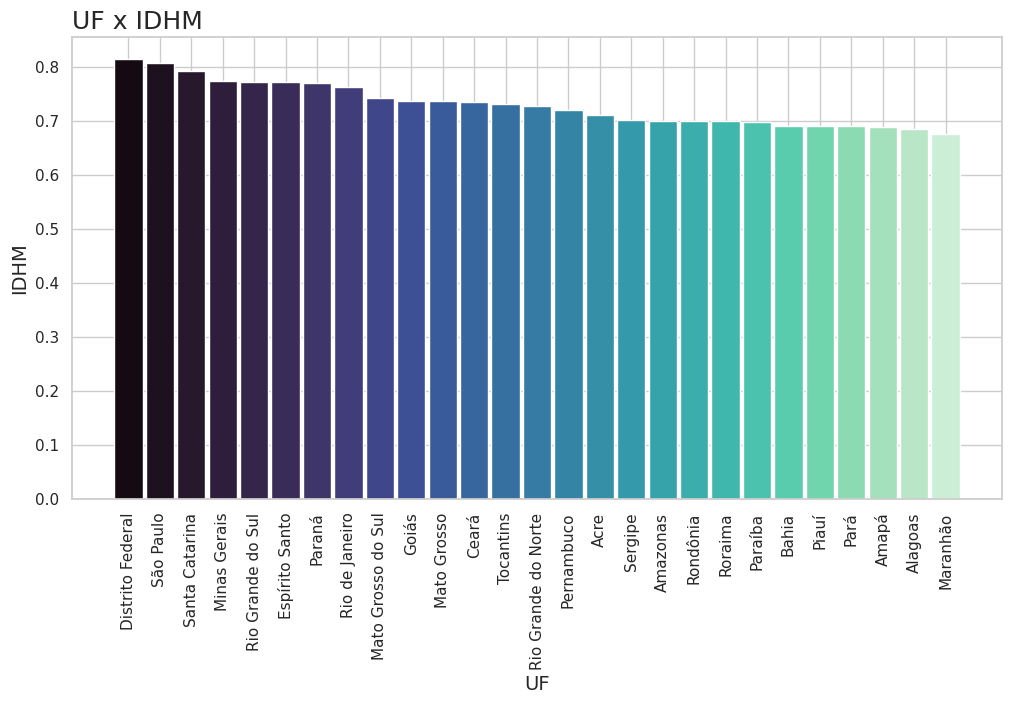

In [422]:
idhm_estados = idhm_estados.sort_values(by='idhm', ascending=False)

#Tamanho do gráfico
plt.figure(figsize=(12, 6))

# Paletas de cores
Paleta_Cores = sns.color_palette('mako', len(idhm_estados))

# Plotagem do gráfico
plt.bar(idhm_estados['estados'],
        idhm_estados['idhm'],
        width=0.9,
        color = Paleta_Cores
        )

# Titulo
plt.title('UF x IDHM', loc= 'left', fontsize=18)

#labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDHM', fontsize = 14)
plt.xticks(rotation=90);

In [423]:
# Mapeando nome do estado -> região

mapa_regiao_nome = {
    "Acre": "Norte",
    "Amapá": "Norte",
    "Amazonas": "Norte",
    "Pará": "Norte",
    "Rondônia": "Norte",
    "Roraima": "Norte",
    "Tocantins": "Norte",

    "Alagoas": "Nordeste",
    "Bahia": "Nordeste",
    "Ceará": "Nordeste",
    "Maranhão": "Nordeste",
    "Paraíba": "Nordeste",
    "Pernambuco": "Nordeste",
    "Piauí": "Nordeste",
    "Rio Grande do Norte": "Nordeste",
    "Sergipe": "Nordeste",

    "Distrito Federal": "Centro-Oeste",
    "Goiás": "Centro-Oeste",
    "Mato Grosso": "Centro-Oeste",
    "Mato Grosso do Sul": "Centro-Oeste",

    "Espírito Santo": "Sudeste",
    "Minas Gerais": "Sudeste",
    "Rio de Janeiro": "Sudeste",
    "São Paulo": "Sudeste",

    "Paraná": "Sul",
    "Rio Grande do Sul": "Sul",
    "Santa Catarina": "Sul",
}

idhm_estados["regiao"] = idhm_estados["estados"].map(mapa_regiao_nome)

idhm_estados[["estados", "regiao"]].drop_duplicates().sort_values("regiao")

,estados,regiao
6,Distrito Federal,Centro-Oeste
11,Mato Grosso do Sul,Centro-Oeste
8,Goiás,Centro-Oeste
10,Mato Grosso,Centro-Oeste
17,Piauí,Nordeste
4,Bahia,Nordeste
14,Paraíba,Nordeste
24,Sergipe,Nordeste
16,Pernambuco,Nordeste
1,Alagoas,Nordeste


In [424]:
idhm_regiao = idhm_estados.groupby("regiao")["idhm"].mean().sort_values()
idhm_regiao.round(2)

,idhm
regiao,
Nordeste,0.70
Norte,0.70
Centro-Oeste,0.76
Sul,0.78
Sudeste,0.78


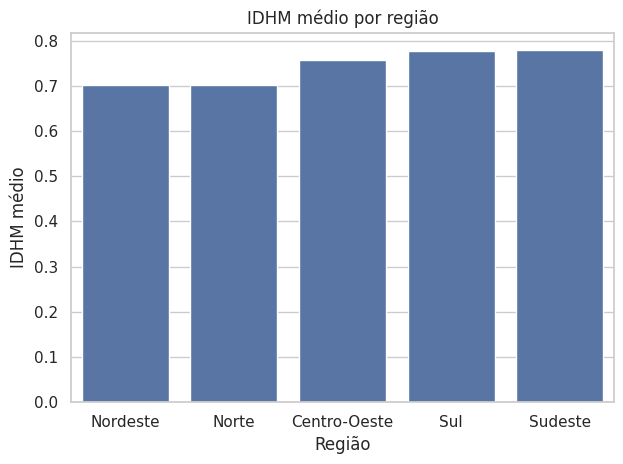

In [425]:
plt.figure()
# Plotagem do gráfico
sns.barplot(x=idhm_regiao.index, y=idhm_regiao.values)
plt.title("IDHM médio por região")
plt.xlabel("Região")
plt.ylabel("IDHM médio")
plt.tight_layout()
plt.show()

/tmp/ipykernel_3768/3450055186.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_educacao, x='estados', y='idhm_educacao', palette='Blues_r')


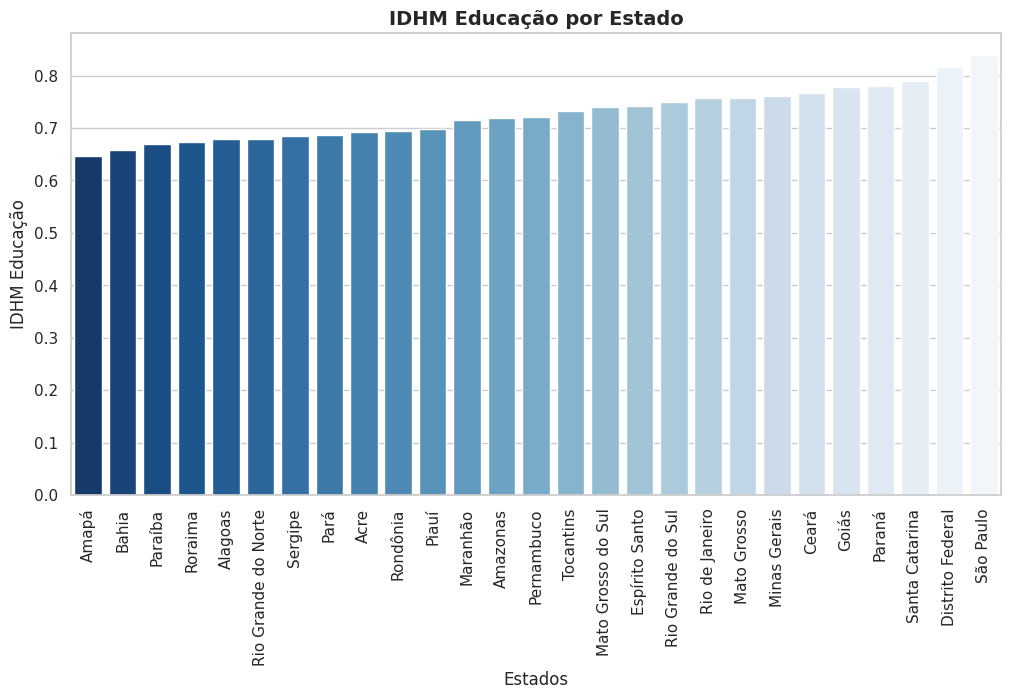

In [426]:


plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Ordena o DataFrame para destacar o ranking
df_educacao = df.sort_values(by='idhm_educacao', ascending=True)

sns.barplot(data=df_educacao, x='estados', y='idhm_educacao', palette='Blues_r')

plt.title('IDHM Educação por Estado', fontsize=14, fontweight='bold')
plt.xlabel('Estados', fontsize=12)
plt.ylabel('IDHM Educação', fontsize=12)
plt.xticks(rotation=90);
plt.show();

/tmp/ipykernel_3768/1189845668.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_longevidade, x='estados', y='idhm_longevidade', palette='Blues_r')


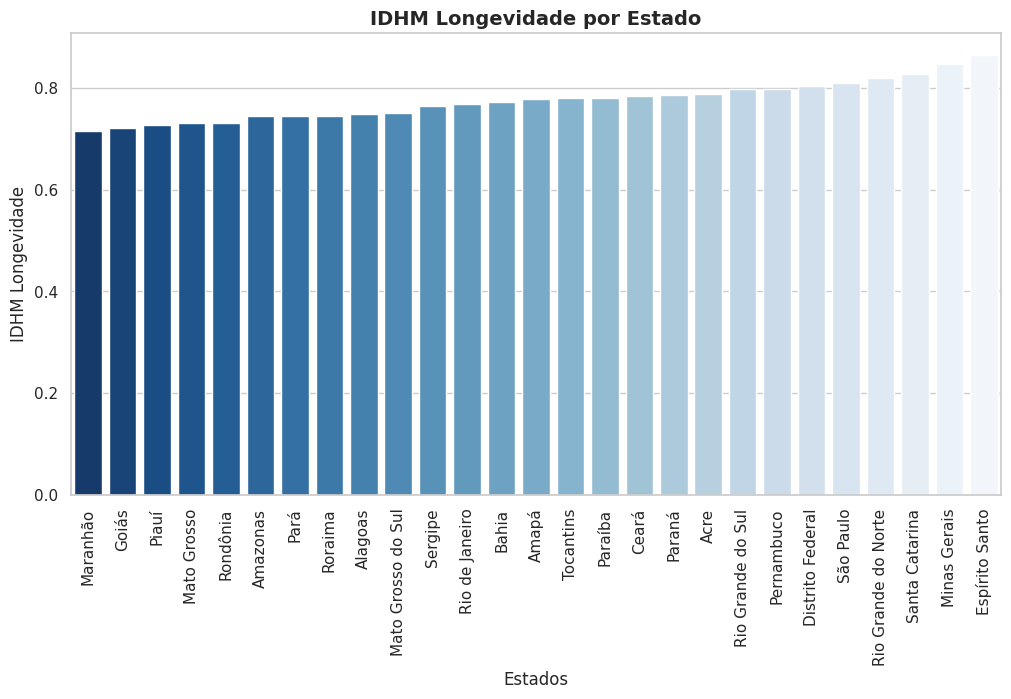

In [427]:

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Ordena o DataFrame para destacar o ranking
df_longevidade = df.sort_values(by='idhm_longevidade', ascending=True)

sns.barplot(data=df_longevidade, x='estados', y='idhm_longevidade', palette='Blues_r')

plt.title('IDHM Longevidade por Estado', fontsize=14, fontweight='bold')
plt.xlabel('Estados', fontsize=12)
plt.ylabel('IDHM Longevidade', fontsize=12)
plt.xticks(rotation=90);
plt.show();

/tmp/ipykernel_3768/4023039966.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_renda, x='estados', y='idhm_renda', palette='Blues_r')


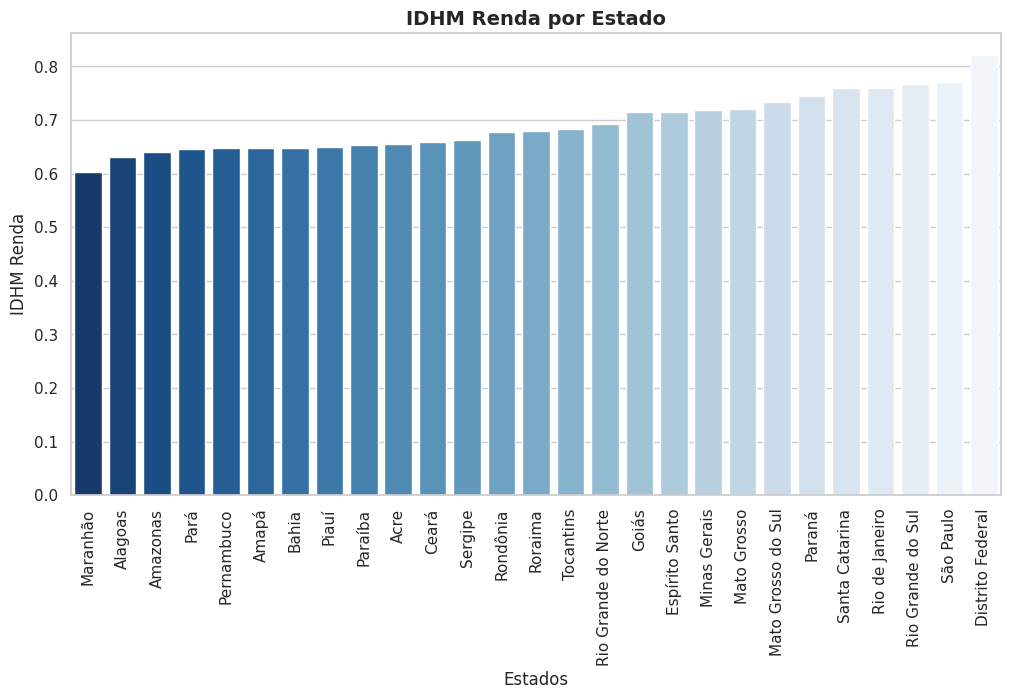

In [428]:

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Ordena o DataFrame para destacar o ranking
df_renda = df.sort_values(by='idhm_renda', ascending=True)

sns.barplot(data=df_renda, x='estados', y='idhm_renda', palette='Blues_r')

plt.title('IDHM Renda por Estado', fontsize=14, fontweight='bold')
plt.xlabel('Estados', fontsize=12)
plt.ylabel('IDHM Renda', fontsize=12)
plt.xticks(rotation=90);
plt.show();

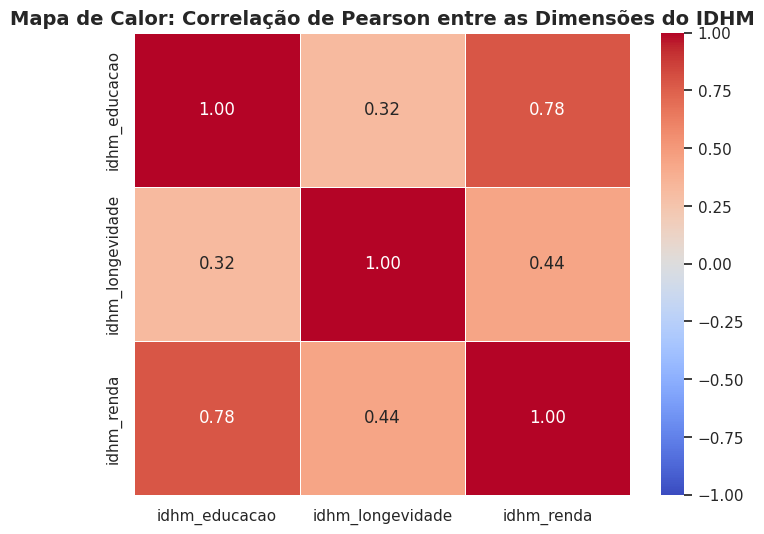

In [436]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

colunas_numericas = ['idhm_educacao', 'idhm_longevidade', 'idhm_renda']
matriz_correlacao = df[colunas_numericas].corr()

# Heatmap com escala corrigida para o coolwarm
sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Mapa de Calor: Correlação de Pearson entre as Dimensões do IDHM', fontsize=14, fontweight='bold')
plt.show()

É possivel perceber correlação entre a educação e a renda

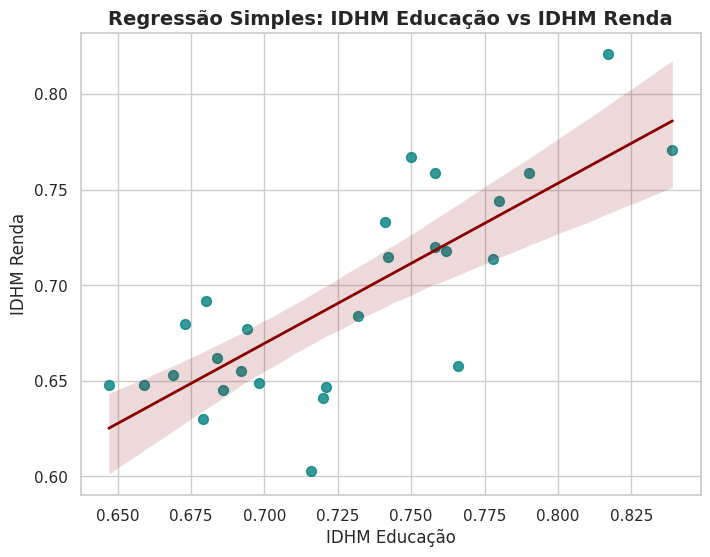

In [430]:


plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Relacionando Educação (Eixo X) com Renda (Eixo Y)
sns.regplot(
    data=df,
    x='idhm_educacao',
    y='idhm_renda',
    color='teal',
    scatter_kws={'alpha': 0.8, 's': 50},
    line_kws={'color': 'darkred', 'linewidth': 2}
)

plt.title('Regressão Simples: IDHM Educação vs IDHM Renda', fontsize=14, fontweight='bold')
plt.xlabel('IDHM Educação', fontsize=12)
plt.ylabel('IDHM Renda', fontsize=12)
plt.show()

/tmp/ipykernel_3768/1778069413.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


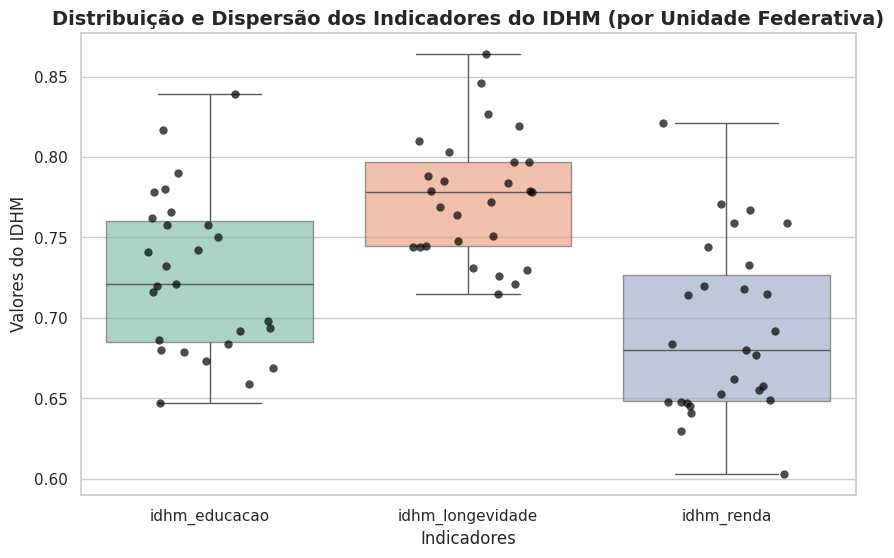

In [435]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Melt mantendo a identidade dos estados
idhm_melted = df.melt(
    id_vars=['estados'],
    value_vars=['idhm_educacao', 'idhm_longevidade', 'idhm_renda'],
    var_name='Indicador',
    value_name='Valor'
)

# Boxplot com transparência para dar destaque aos pontos
sns.boxplot(
    data=idhm_melted,
    x='Indicador',
    y='Valor',
    palette='Set2',
    boxprops=dict(alpha=0.6),
    showfliers=False # Oculta outliers automáticos do boxplot para limpar com o stripplot
)

# Sobreposição dos pontos dos estados
sns.stripplot(
    data=idhm_melted,
    x='Indicador',
    y='Valor',
    color='black',
    alpha=0.7,
    jitter=0.25,
    size=6
)

plt.title('Distribuição e Dispersão dos Indicadores do IDHM (por Unidade Federativa)', fontsize=14, fontweight='bold')
plt.xlabel('Indicadores', fontsize=12)
plt.ylabel('Valores do IDHM', fontsize=12)
plt.show()

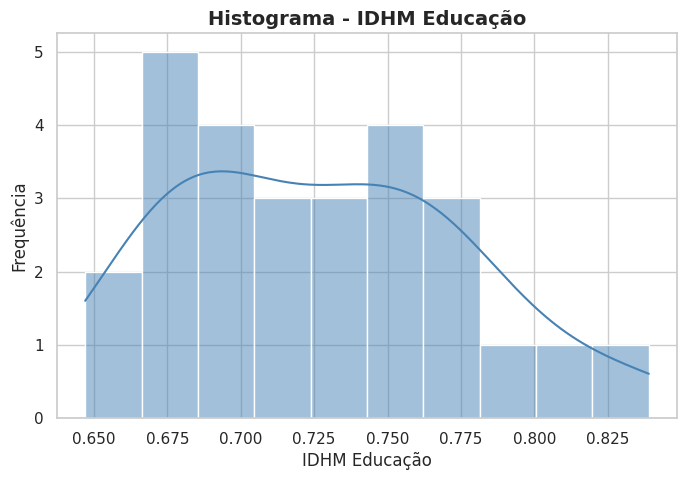

In [432]:
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Plota o histograma com a curva de densidade (KDE)
sns.histplot(df['idhm_educacao'], kde=True, color='steelblue', bins=10)

plt.title('Histograma - IDHM Educação', fontsize=14, fontweight='bold')
plt.xlabel('IDHM Educação', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.show()

O cruzamento dos dados revela que as dimensões do desenvolvimento humano operam com lógicas distintas no território brasileiro. Enquanto educação e renda possuem uma correlação forte e positiva ($r = 0,78$, gerando um $r^2 \approx 0,61$, o que indica que cerca de 61% da variância da renda é explicada pela educação), as relações envolvendo longevidade são consideravelmente mais fracas: educação e longevidade registram $r = 0,32$, e renda e longevidade ficam em $r = 0,44$.

Isso significa que um estado avançar em termos de expectativa de vida não garante, na mesma proporção, avanços idênticos em renda ou educação. Para ilustrar essa desconexão na prática, basta comparar os perfis de estados como Goiás e Rio Grande do Norte: eles podem apresentar proximidade em uma dimensão (como longevidade), mas divergem de forma expressiva nos indicadores de educação ou renda.

Limites Metodológicos e Cuidados Analíticos:Tamanho amostral ($n = 27$): O universo restrito às 27 unidades federativas exige cautela em generalizações estatísticas profundas.

Unidade de análise: O recorte é o estado federativo; portanto, desigualdades intrarregionais profundas (entre municípios ou bairros) ficam invisibilizadas pela agregação macro.

Causalidade: Correlação forte ($0,78$) não implica causalidade direta; fatores estruturais e históricos subjacentes impulsionam ambos os indicadores simultaneamente.

Sensibilidade a pontos influentes: É altamente recomendável rodar um teste de robustez para verificar se o coeficiente de correlação de $0,78$ entre educação e renda se mantém estável ou se sofre forte impacto caso o Distrito Federal seja removido da análise.